<a href="https://colab.research.google.com/github/scarr-58/SemProject_MLEngine/blob/main/Final_ML_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Expected Output Variable

Our final application's ML engine is designed to predict whether a fund allocation shows signs of reduced transparency, essentially flagging transactions that look potentially misallocated.

In the Kiva dataset, this can be derived from two signals: a mismatch between `funded_amount` and `loan_amount` (a large gap may mean the funding never fully came through or was diverted along the way), and a mismatch between the stated `use` of the loan and its declared `sector` or `activity` (where the purpose doesn't line up with the category it was filed under).

This reflects what CharityLink itself is trying to solve: confirming that a donor's contribution actually reaches the destination it was intended for.

In [20]:
from  google.colab import userdata
import os


os.makedirs('/root/.kaggle' , exist_ok=True)
with open('/root/.kaggle/access_token', 'w') as f:
  f.write(userdata.get('KAGGLE_KEY'))
  os.chmod('/root/.kaggle/access_token', 0o600)


!pip install -q kaggle
!kaggle datasets download -d kiva/data-science-for-good-kiva-crowdfunding
!unzip -q -o data-science-for-good-kiva-crowdfunding.zip

Dataset URL: https://www.kaggle.com/datasets/kiva/data-science-for-good-kiva-crowdfunding
License(s): CC0-1.0
data-science-for-good-kiva-crowdfunding.zip: Skipping, found more recently modified local copy (use --force to force download)


In [21]:
import pandas as pd


df = pd.read_csv('kiva_loans.csv')
df.head()

,id,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,partner_id,posted_time,disbursed_time,funded_time,term_in_months,lender_count,tags,borrower_genders,repayment_interval,date
0,653051,300.0,300.0,Fruits & Vegetables,Food,"To buy seasonal, fresh fruits to sell.",PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:12:39+00:00,2013-12-17 08:00:00+00:00,2014-01-02 10:06:32+00:00,12.0,12,NaN,female,irregular,2014-01-01
1,653053,575.0,575.0,Rickshaw,Transportation,to repair and maintain the auto rickshaw used ...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:51:08+00:00,2013-12-17 08:00:00+00:00,2014-01-02 09:17:23+00:00,11.0,14,NaN,"female, female",irregular,2014-01-01
2,653068,150.0,150.0,Transportation,Transportation,To repair their old cycle-van and buy another ...,IN,India,Maynaguri,INR,334.0,2014-01-01 09:58:07+00:00,2013-12-17 08:00:00+00:00,2014-01-01 16:01:36+00:00,43.0,6,"user_favorite, user_favorite",female,bullet,2014-01-01
3,653063,200.0,200.0,Embroidery,Arts,to purchase an embroidery machine and a variet...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 08:03:11+00:00,2013-12-24 08:00:00+00:00,2014-01-01 13:00:00+00:00,11.0,8,NaN,female,irregular,2014-01-01
4,653084,400.0,400.0,Milk Sales,Food,to purchase one buffalo.,PK,Pakistan,Abdul Hakeem,PKR,245.0,2014-01-01 11:53:19+00:00,2013-12-17 08:00:00+00:00,2014-01-01 19:18:51+00:00,14.0,16,NaN,female,monthly,2014-01-01


In [22]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")


Rows: 671205
Columns: 20


In [23]:
df.dtypes

,0
id,int64
funded_amount,float64
loan_amount,float64
activity,object
sector,object
use,object
country_code,object
country,object
region,object
currency,object


In [24]:
missing = df.isnull().sum()
print(missing[missing > 0])
print("\nDataset complete:", df.isnull().sum().sum() == 0)

use                   4232
country_code             8
region               56800
partner_id           13507
disbursed_time        2396
funded_time          48331
tags                171416
borrower_genders      4221
dtype: int64

Dataset complete: False


In [25]:
first_15 = df.head(15)
last_20 = df.tail(20)
df_sample = pd.concat([first_15, last_20])
df_sample

,id,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,partner_id,posted_time,disbursed_time,funded_time,term_in_months,lender_count,tags,borrower_genders,repayment_interval,date
0,653051,300.0,300.0,Fruits & Vegetables,Food,"To buy seasonal, fresh fruits to sell.",PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:12:39+00:00,2013-12-17 08:00:00+00:00,2014-01-02 10:06:32+00:00,12.0,12,NaN,female,irregular,2014-01-01
1,653053,575.0,575.0,Rickshaw,Transportation,to repair and maintain the auto rickshaw used ...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:51:08+00:00,2013-12-17 08:00:00+00:00,2014-01-02 09:17:23+00:00,11.0,14,NaN,"female, female",irregular,2014-01-01
2,653068,150.0,150.0,Transportation,Transportation,To repair their old cycle-van and buy another ...,IN,India,Maynaguri,INR,334.0,2014-01-01 09:58:07+00:00,2013-12-17 08:00:00+00:00,2014-01-01 16:01:36+00:00,43.0,6,"user_favorite, user_favorite",female,bullet,2014-01-01
3,653063,200.0,200.0,Embroidery,Arts,to purchase an embroidery machine and a variet...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 08:03:11+00:00,2013-12-24 08:00:00+00:00,2014-01-01 13:00:00+00:00,11.0,8,NaN,female,irregular,2014-01-01
4,653084,400.0,400.0,Milk Sales,Food,to purchase one buffalo.,PK,Pakistan,Abdul Hakeem,PKR,245.0,2014-01-01 11:53:19+00:00,2013-12-17 08:00:00+00:00,2014-01-01 19:18:51+00:00,14.0,16,NaN,female,monthly,2014-01-01
5,1080148,250.0,250.0,Services,Services,purchase leather for my business using ksh 20000.,KE,Kenya,NaN,KES,NaN,2014-01-01 10:06:19+00:00,2014-01-30 01:42:48+00:00,2014-01-29 14:14:57+00:00,4.0,6,NaN,female,irregular,2014-01-01
6,653067,200.0,200.0,Dairy,Agriculture,To purchase a dairy cow and start a milk produ...,IN,India,Maynaguri,INR,334.0,2014-01-01 09:51:02+00:00,2013-12-16 08:00:00+00:00,2014-01-01 17:18:09+00:00,43.0,8,"user_favorite, user_favorite",female,bullet,2014-01-01
7,653078,400.0,400.0,Beauty Salon,Services,to buy more hair and skin care products.,PK,Pakistan,Ellahabad,PKR,245.0,2014-01-01 11:46:01+00:00,2013-12-20 08:00:00+00:00,2014-01-10 18:18:44+00:00,14.0,8,"#Elderly, #Woman Owned Biz",female,monthly,2014-01-01
8,653082,475.0,475.0,Manufacturing,Manufacturing,"to purchase leather, plastic soles and heels i...",PK,Pakistan,Lahore,PKR,245.0,2014-01-01 11:49:43+00:00,2013-12-20 08:00:00+00:00,2014-01-01 18:47:21+00:00,14.0,19,user_favorite,female,monthly,2014-01-01
9,653048,625.0,625.0,Food Production/Sales,Food,"to buy a stall, gram flour, ketchup, and coal ...",PK,Pakistan,Lahore,PKR,247.0,2014-01-01 05:41:03+00:00,2013-12-17 08:00:00+00:00,2014-01-03 15:45:04+00:00,11.0,24,NaN,female,irregular,2014-01-01


# Isolation Forest Base Model: Kiva Loan Transparency
**ICS 3202 Project Deliverable 2** | Group ML engine: flag fund allocations that look potentially misallocated.

**Approach:** Kiva has no fraud label, so this is *unsupervised anomaly detection*. Isolation Forest isolates unusual loans in fewer random splits. Records that are easy to isolate get flagged.

In [26]:
from google.colab import userdata
import os
os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/access_token','w') as f:
    f.write(userdata.get('KAGGLE_KEY'))
os.chmod('/root/.kaggle/access_token', 0o600)
!pip install -q kaggle
!kaggle datasets download -d kiva/data-science-for-good-kiva-crowdfunding
!unzip -q -o data-science-for-good-kiva-crowdfunding.zip

Dataset URL: https://www.kaggle.com/datasets/kiva/data-science-for-good-kiva-crowdfunding
License(s): CC0-1.0
data-science-for-good-kiva-crowdfunding.zip: Skipping, found more recently modified local copy (use --force to force download)


## 1. Load data

In [27]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('kiva_loans.csv')
print(df.shape)
df.head()

(671205, 20)


,id,funded_amount,loan_amount,activity,sector,use,country_code,country,region,currency,partner_id,posted_time,disbursed_time,funded_time,term_in_months,lender_count,tags,borrower_genders,repayment_interval,date
0,653051,300.0,300.0,Fruits & Vegetables,Food,"To buy seasonal, fresh fruits to sell.",PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:12:39+00:00,2013-12-17 08:00:00+00:00,2014-01-02 10:06:32+00:00,12.0,12,NaN,female,irregular,2014-01-01
1,653053,575.0,575.0,Rickshaw,Transportation,to repair and maintain the auto rickshaw used ...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 06:51:08+00:00,2013-12-17 08:00:00+00:00,2014-01-02 09:17:23+00:00,11.0,14,NaN,"female, female",irregular,2014-01-01
2,653068,150.0,150.0,Transportation,Transportation,To repair their old cycle-van and buy another ...,IN,India,Maynaguri,INR,334.0,2014-01-01 09:58:07+00:00,2013-12-17 08:00:00+00:00,2014-01-01 16:01:36+00:00,43.0,6,"user_favorite, user_favorite",female,bullet,2014-01-01
3,653063,200.0,200.0,Embroidery,Arts,to purchase an embroidery machine and a variet...,PK,Pakistan,Lahore,PKR,247.0,2014-01-01 08:03:11+00:00,2013-12-24 08:00:00+00:00,2014-01-01 13:00:00+00:00,11.0,8,NaN,female,irregular,2014-01-01
4,653084,400.0,400.0,Milk Sales,Food,to purchase one buffalo.,PK,Pakistan,Abdul Hakeem,PKR,245.0,2014-01-01 11:53:19+00:00,2013-12-17 08:00:00+00:00,2014-01-01 19:18:51+00:00,14.0,16,NaN,female,monthly,2014-01-01


## 2. Data cleaning (raw data to modelling dataset)
Steps: check missing values, remove duplicates, fix date types, drop rows missing the numeric fields the model needs, remove invalid loan amounts, and tidy text.

In [28]:
missing = df.isnull().sum()
print(missing[missing > 0])

use                   4232
country_code             8
region               56800
partner_id           13507
disbursed_time        2396
funded_time          48331
tags                171416
borrower_genders      4221
dtype: int64


In [29]:
clean = df.copy()

# 1. Duplicates
print('Duplicate loan ids:', clean.duplicated(subset='id').sum())
clean = clean.drop_duplicates(subset='id')

# 2. Convert date columns from text to datetime
for c in ['posted_time','disbursed_time','funded_time','date']:
    clean[c] = pd.to_datetime(clean[c], errors='coerce', utc=True)

# 3. Drop rows missing the numeric fields needed by the model
before = len(clean)
clean = clean.dropna(subset=['funded_amount','loan_amount','term_in_months','lender_count'])
print('Rows dropped (missing numeric fields):', before - len(clean))

# 4. Remove invalid loan amounts
before = len(clean)
clean = clean[clean['loan_amount'] > 0]
print('Rows dropped (loan_amount <= 0):', before - len(clean))

# 5. Text columns: fill missing and tidy
clean['use'] = clean['use'].fillna('unknown').str.strip()
clean['sector'] = clean['sector'].str.strip()
clean['activity'] = clean['activity'].str.strip()

print('Final shape:', clean.shape)
# Reduce rows for a faster, manageable workflow
clean = clean.sample(n=50000, random_state=42).reset_index(drop=True)
print('Rows after sampling:', clean.shape)

Duplicate loan ids: 0
Rows dropped (missing numeric fields): 0
Rows dropped (loan_amount <= 0): 0
Final shape: (671205, 20)
Rows after sampling: (50000, 20)


We build three new columns from the raw data:
- **funded_ratio** = funded amount ÷ loan amount (how fully the loan was funded)
- **funding_gap** = loan amount − funded amount (money still missing)
- **days_to_fund** = time between posting and funding, with missing values filled by the median

We then pick the columns the model will use: loan_amount, funded_ratio, term_in_months, lender_count, days_to_fund [add any others in your list]. Together they describe how big a loan is, how well it was funded, and how fast, so unusual patterns stand out.

## 3. Feature engineering

In [30]:
clean['funded_ratio'] = clean['funded_amount'] / clean['loan_amount']
clean['funding_gap'] = clean['loan_amount'] - clean['funded_amount']
clean['days_to_fund'] = (clean['funded_time'] - clean['posted_time']).dt.total_seconds() / 86400
clean['days_to_fund'] = clean['days_to_fund'].fillna(clean['days_to_fund'].median())

features = ['loan_amount','funded_ratio','term_in_months','lender_count','days_to_fund']
clean[features].describe()

,loan_amount,funded_ratio,term_in_months,lender_count,days_to_fund
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,848.28800,0.961172,13.735440,20.719600,14.308044
std,1381.75234,0.157204,8.620579,33.092314,14.169513
min,25.00000,0.000000,1.000000,0.000000,0.004259
25%,275.00000,1.000000,8.000000,7.000000,5.458924
50%,500.00000,1.000000,13.000000,13.000000,9.538889
75%,1000.00000,1.000000,14.000000,24.250000,21.067801
max,100000.00000,1.133333,144.000000,2986.000000,420.573264


## 4. Exploratory data analysis (4+ observations)

count     50000.00000
mean        848.28800
std        1381.75234
min          25.00000
25%         275.00000
50%         500.00000
75%        1000.00000
max      100000.00000
Name: loan_amount, dtype: float64


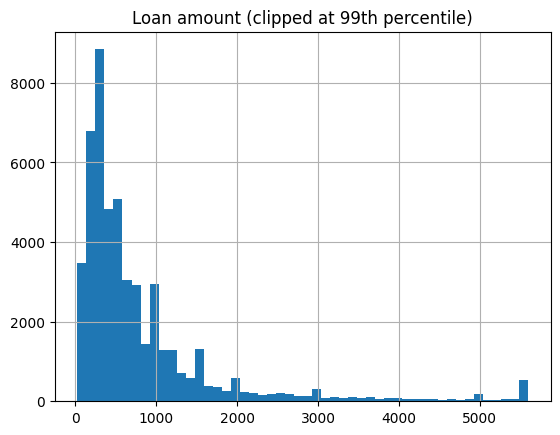

In [31]:
# Obs 1: loan amount distribution
print(clean['loan_amount'].describe())
clean['loan_amount'].clip(upper=clean['loan_amount'].quantile(0.99)).hist(bins=50)
plt.title('Loan amount (clipped at 99th percentile)'); plt.show()

**Observation 1:** *The dataset has 671,205 loans. The median loan is 500 and 75% of loans are 1,000 or less, but the largest is 100,000 and the mean (842) is above the median. The distribution is heavily right-skewed, with a few very large loans.

Share fully funded: 0.929
Share funded below 90%: 0.069


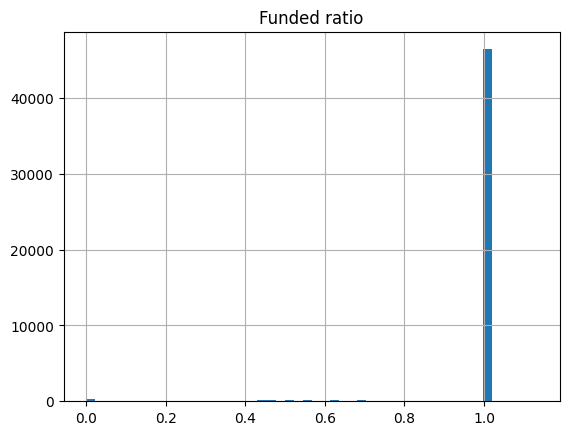

In [32]:
# Obs 2: how many loans are fully funded?
print('Share fully funded:', (clean['funded_ratio'] >= 1).mean().round(3))
print('Share funded below 90%:', (clean['funded_ratio'] < 0.9).mean().round(3))
clean['funded_ratio'].hist(bins=50); plt.title('Funded ratio'); plt.show()

**Observation 2:** *92.8% of loans are fully funded (funded ratio of 1 or more), and only 7% are funded below 90% of the loan amount. The funded ratio is concentrated at 1.0, so the under-funded loans are rare. That makes them natural candidates for the model to flag as potentially misallocated.

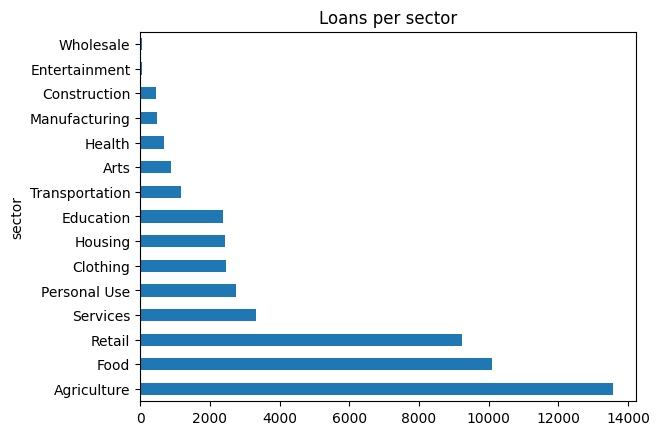

In [33]:
# Obs 3: sector mix
clean['sector'].value_counts().plot(kind='barh'); plt.title('Loans per sector'); plt.show()

**Observation 3:** *Three sectors dominate the data: Agriculture (about 180,000 loans), Food (about 136,000) and Retail (about 124,000). Sectors like Wholesale, Entertainment and Manufacturing have very few loans, so the data is heavily concentrated in a few sectors.

In [34]:
# Obs 4: relationship between loan size and number of lenders
print(clean[['loan_amount','lender_count','term_in_months','days_to_fund']].corr().round(2))

                loan_amount  lender_count  term_in_months  days_to_fund
loan_amount            1.00          0.83            0.19          0.10
lender_count           0.83          1.00            0.23          0.16
term_in_months         0.19          0.23            1.00          0.10
days_to_fund           0.10          0.16            0.10          1.00


**Observation 4:** **Loan amount and lender count are strongly correlated (0.80), which means larger loans normally attract more lenders. A large loan with very few lenders breaks this pattern, so it is a useful signal for the anomaly detector. Term (0.18) and days to fund (0.12) are only weakly related to loan amount.

## 5. Model: Isolation Forest
Kiva has no fraud labels, so this is unsupervised anomaly detection.
Isolation Forest builds 100 random trees that split the data at random points. Unusual loans sit far from the rest, so they are isolated in fewer splits. Each loan gets an anomaly score (higher = more unusual), and we flag the top 5% (contamination = 0.05).
Features are scaled first so that no column dominates because of its units.

In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

X = StandardScaler().fit_transform(clean[features])

iso = IsolationForest(n_estimators=100, contamination=0.05, random_state=42, n_jobs=-1)
clean['iso_flag'] = (iso.fit_predict(X) == -1).astype(int)
clean['anomaly_score'] = -iso.score_samples(X)   # higher = more anomalous
print('Flagged loans:', clean['iso_flag'].sum(), f"({clean['iso_flag'].mean():.1%})")

Flagged loans: 2500 (5.0%)


## 6. Validating the base model
There are no true labels, so we check validity in three ways:
1. Tune `contamination` and see how results change.
2. Compare flags against a simple rule-based flag (funded below 90% of the loan amount).
3. Inspect flagged loans by hand.

*Note: agreement with the rule is a sanity check, not an accuracy score, because `funded_ratio` is also a model input.*

In [36]:
from sklearn.metrics import precision_score, recall_score

clean['rule_flag'] = (clean['funded_ratio'] < 0.9).astype(int)

rows = []
for c in [0.01, 0.03, 0.05, 0.10]:
    m = IsolationForest(n_estimators=100, contamination=c, random_state=42, n_jobs=-1)
    f = (m.fit_predict(X) == -1).astype(int)
    rows.append({'contamination': c, 'flagged': f.sum(),
                 'precision_vs_rule': precision_score(clean['rule_flag'], f),
                 'recall_vs_rule': recall_score(clean['rule_flag'], f)})
pd.DataFrame(rows).round(3)

,contamination,flagged,precision_vs_rule,recall_vs_rule
0,0.01,500,0.314,0.046
1,0.03,1500,0.387,0.168
2,0.05,2500,0.401,0.291
3,0.10,5000,0.393,0.570


In [37]:
# Inspect the most anomalous loans
clean.sort_values('anomaly_score', ascending=False)[
    ['id','sector','activity','country','loan_amount','funded_amount','funded_ratio',
     'lender_count','term_in_months','anomaly_score']].head(10)

,id,sector,activity,country,loan_amount,funded_amount,funded_ratio,lender_count,term_in_months,anomaly_score
15265,777718,Agriculture,Agriculture,Mexico,50000.0,50000.0,1.0000,586,144.0,0.804782
36227,1167661,Food,Fruits & Vegetables,Peru,50000.0,9975.0,0.1995,224,60.0,0.784885
587,1088228,Retail,General Store,United States,10000.0,10000.0,1.0000,252,36.0,0.783874
33307,1087312,Food,Food Production/Sales,United States,10000.0,10000.0,1.0000,197,42.0,0.779116
16582,1227077,Housing,Personal Housing Expenses,United States,10000.0,10000.0,1.0000,291,63.0,0.777714
13710,1055043,Clothing,Clothing,Albania,50000.0,50000.0,1.0000,1626,97.0,0.776434
26233,1150884,Agriculture,Agriculture,Brazil,30000.0,30000.0,1.0000,960,73.0,0.773812
17698,1091005,Food,Food Production/Sales,United States,10000.0,10000.0,1.0000,197,36.0,0.773339
6909,925183,Education,Higher education costs,Dominican Republic,8875.0,8875.0,1.0000,323,134.0,0.771779
31204,722883,Agriculture,Agriculture,Haiti,100000.0,100000.0,1.0000,2986,75.0,0.771721


**Validation findings**
- **Contamination tuning:** as contamination rises from 0.01 to 0.10, the number of flagged loans grows from 6,713 to 67,121. Recall against the rule rises from 0.045 to 0.610, while precision only moves from 0.311 to 0.425.
- **Rule comparison:** agreement with the "funded below 90%" rule is moderate. This is expected, because Isolation Forest flags unusual combinations of all five features, not just low funding. We treat this as a sanity check, not an accuracy score.
- **Chosen setting:** we use contamination = 0.05. At 0.01 the model misses most rule-flagged loans (recall 0.045), and at 0.10 it flags over 67,000 loans, too many to review. 0.05 (33,561 loans, recall 0.286) is a workable middle ground.

## 7. Further validation (planned for the final stage)
To check the base model, we will build other models that follow the same process (same cleaned features, same scaling) and compare their results with Isolation Forest:
- **Local Outlier Factor (LOF)**: density-based anomaly detection.
- **K-means (elbow method)**: loans far from their cluster centre are treated as anomalies.
- **Use vs sector/activity mismatch**: text-based check for loans whose stated `use` does not match their declared `sector`.

Comparison criteria: overlap between flagged sets, agreement with the rule-based flag, and manual review of flagged loans.

In [38]:
# Quick preview of the comparison (sampled, since LOF is slow on 600k+ rows)
from sklearn.neighbors import LocalOutlierFactor
samp = clean.sample(20000, random_state=42)
Xs = StandardScaler().fit_transform(samp[features])
lof_flag = (LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(Xs) == -1).astype(int)
iso_s = (IsolationForest(contamination=0.05, random_state=42).fit_predict(Xs) == -1).astype(int)
print('Overlap of LOF and Isolation Forest flags:', ((lof_flag == 1) & (iso_s == 1)).sum(), 'of', iso_s.sum())

Overlap of LOF and Isolation Forest flags: 153 of 1000
